In [6]:
# LAB ASSIGNMENT 8: NLP AND TOPIC MODELLING

!pip install -q nltk wordcloud pyLDAvis scikit-learn

import pandas as pd
import re
import nltk
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display, HTML
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from collections import Counter
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import pyLDAvis
import pyLDAvis.lda_model

In [14]:
# TASK 1: DATA PREPROCESSING AND CLEANING

# Upload the downloaded CSV file once
df = pd.read_csv('/content/Health_Related_Headlines_Dataset.csv')

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

# Download required NLTK resources
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# Automatically identify text columns
text_columns = df.select_dtypes(include=['object', 'string']).columns.tolist()

if not text_columns:
    raise ValueError("No text columns found in the dataset.")

Shape: (39405, 5)
Columns: ['Date', 'Source', 'Headlines', 'Teaser', 'Category']


,Date,Source,Headlines,Teaser,Category
0,"January, 1970",Medscape Special Reports,Special Report: Adult Vaccines -- New ACIP Rec...,New recommendations for already approved vacci...,Immunization
1,"January, 1970",Medscape Medical News,Combined Internet and Telephone Intervention M...,"In a randomized trial, combined Internet and t...",Substance Abuse and Addiction
2,"April, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Link Between Parental Alcoholism and Childhood...,It is proposed that depressed children identif...,Substance Abuse and Addiction
3,"November, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Methadone Dose in the Treatment of Opiate Depe...,The epidemic of heroin abuse within the US has...,Substance Abuse and Addiction
4,"March, 2000",Medscape Medical News,Magnet Treatment Had No Beneficial Effect on P...,A small study using one variety of magnet for ...,Pain Management


In [15]:
# Combine available text columns into one corpus
df['Text'] = df[text_columns].fillna('').astype(str).agg(' '.join, axis=1)

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()
def clean_text(text):
    # Lowercasing
    text = str(text).lower()
    # Remove punctuation, numbers and special characters
    text = re.sub(r'[^a-z\s]', ' ', text)
    # Tokenization
    tokens = word_tokenize(text)
    # Stop-word removal and lemmatization
    cleaned_words = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]
    return ' '.join(cleaned_words)
df['Cleaned_Text'] = df['Text'].apply(clean_text)

In [16]:
# Remove empty documents
df = df[df['Cleaned_Text'].str.strip() != ''].copy()
df.reset_index(drop=True, inplace=True)
print("\nTASK 1: CLEANED TEXT SAMPLES")
display(df[['Text', 'Cleaned_Text']].head(5))


TASK 1: CLEANED TEXT SAMPLES


,Text,Cleaned_Text
0,"January, 1970 Medscape Special Reports Speci...",january medscape special report special report...
1,"January, 1970 Medscape Medical News Combined...",january medscape medical news combined interne...
2,"April, 1997 Medscape Psychiatry & Mental Hea...",april medscape psychiatry mental health ejourn...
3,"November, 1997 Medscape Psychiatry & Mental ...",november medscape psychiatry mental health ejo...
4,"March, 2000 Medscape Medical News Magnet Tre...",march medscape medical news magnet treatment b...


In [17]:
# TASK 2: EXPLORATORY TEXT ANALYSIS AND WORD VISUALIZATION

# Word frequency distribution
all_words = ' '.join(df['Cleaned_Text']).split()
word_frequency = Counter(all_words)
print("\nWORD FREQUENCY DISTRIBUTION")
frequency_df = pd.DataFrame(
    word_frequency.most_common(),
    columns=['Word', 'Frequency']
)
display(frequency_df.head(20))


WORD FREQUENCY DISTRIBUTION


,Word,Frequency
0,medscape,20778
1,patient,18884
2,pain,15020
3,medical,14809
4,news,14312
5,clinical,12693
6,trial,12419
7,management,11171
8,drug,10738
9,may,8675


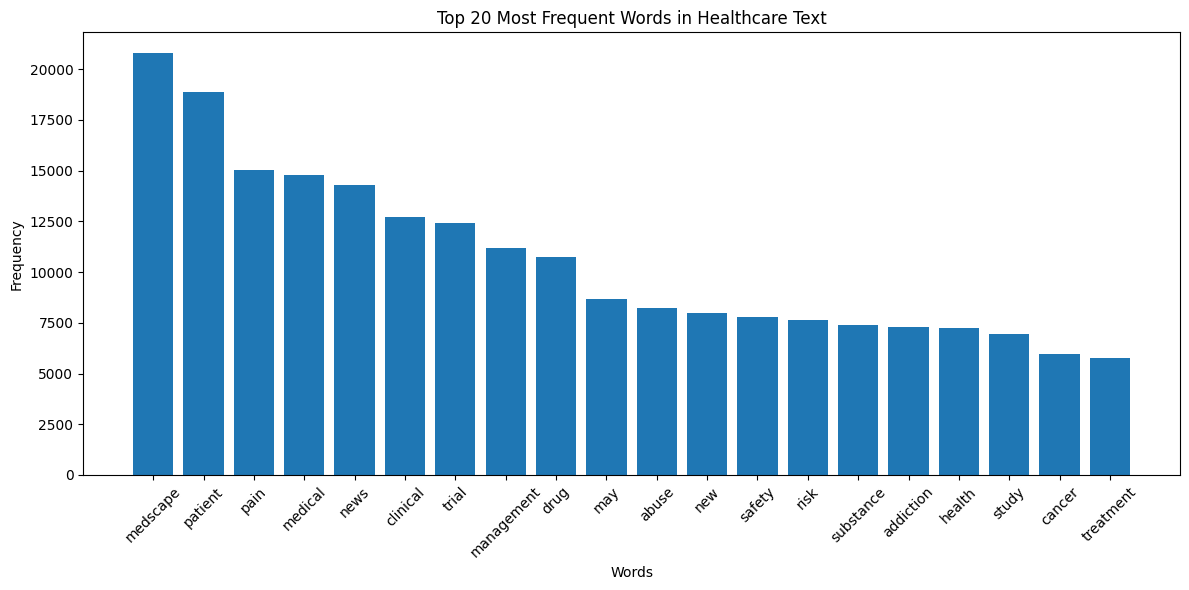

In [18]:
# Plot top 20 frequent words
top_20 = frequency_df.head(20)
plt.figure(figsize=(12, 6))
plt.bar(top_20['Word'], top_20['Frequency'])
plt.title('Top 20 Most Frequent Words in Healthcare Text')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

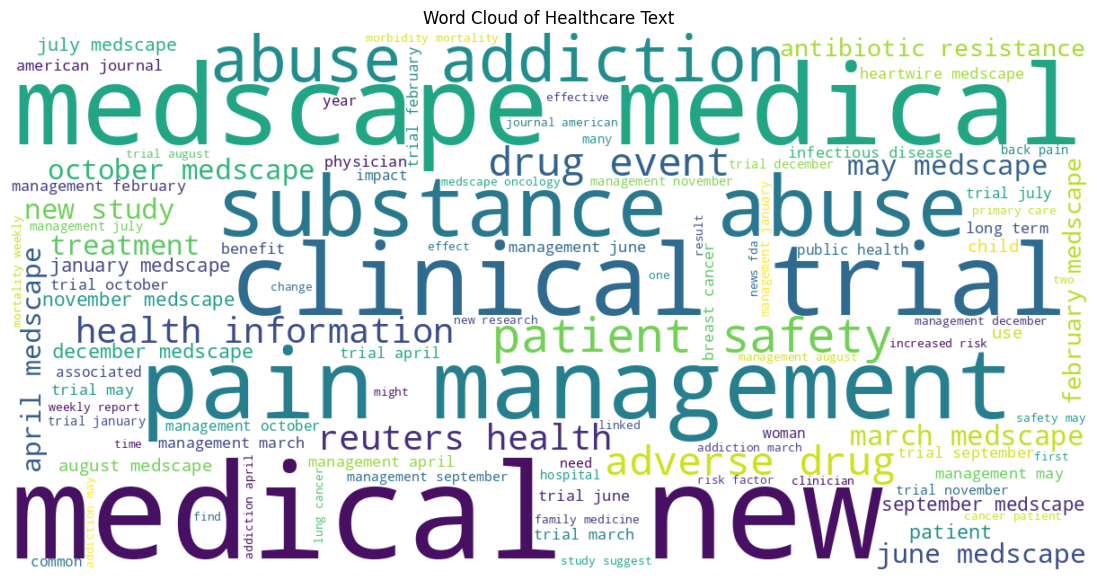

In [19]:
# Generate Word Cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=100
).generate(' '.join(df['Cleaned_Text']))
plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Healthcare Text')
plt.show()

In [22]:
# TASK 3: TOPIC MODELLING USING LDA

vectorizer = CountVectorizer(
    max_features=2000,
    min_df=2,
    max_df=0.95
)
document_term_matrix = vectorizer.fit_transform(df['Cleaned_Text'])
print("Document-Term Matrix Shape:",
      document_term_matrix.shape)

Document-Term Matrix Shape: (39405, 2000)


In [23]:
# Train LDA model with 5 topics
lda_model = LatentDirichletAllocation(
    n_components=5,
    random_state=42,
    max_iter=10,
    learning_method='batch'
)
lda_model.fit(document_term_matrix)

LatentDirichletAllocation(n_components=5, random_state=42)

In [24]:
# Display top 5 words per topic
feature_names = vectorizer.get_feature_names_out()
print("\nTOP 5 WORDS PER TOPIC")
for topic_number, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-5:][::-1]
    top_words = [feature_names[i] for i in top_indices]
    print(f"Topic {topic_number + 1}: {', '.join(top_words)}")


TOP 5 WORDS PER TOPIC
Topic 1: medscape, trial, clinical, cancer, medical
Topic 2: medscape, patient, medical, news, safety
Topic 3: clinical, trial, disease, antibiotic, journal
Topic 4: abuse, risk, substance, addiction, medscape
Topic 5: pain, management, patient, medscape, medical


In [26]:
# Interactive visualization using pyLDAvis
print("Preparing pyLDAvis visualization...")
lda_visualization = pyLDAvis.lda_model.prepare(
    lda_model,
    document_term_matrix,
    vectorizer,
    mds='pcoa'
)
display(HTML(pyLDAvis.prepared_data_to_html(lda_visualization)))

Preparing pyLDAvis visualization...
